# EOD electric-field solver — multi-fish, two-layer bodies, recorded waveform

Extends the single-fish resistive pipeline with:
- **Two-layer fish**: conductive **interior** + resistive/capacitive **skin** (literature values).
- **Recorded EOD** as the source waveform `I(t)` (first row, most active electrode).
- **Per-fish solve**: each of the 4 fish takes a turn as the emitter; the *other* fish enter as skin+interior boundaries.

Governing equation (frequency domain, one ω):
$$\nabla\cdot(\gamma\,\nabla\hat\varphi) = -\hat s,\qquad \gamma=\sigma+i\omega\varepsilon$$
solved per kept EOD frequency, then inverse-FFT to `φ(t)`.

In [1]:
import numpy as np, pandas as pd, re
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.ndimage import zoom, binary_erosion
import matplotlib.pyplot as plt

## 0. Load fish masks
`mask_example_3_frames.npy` -> `(n_frames, n_fish, P, P)`. We take frame 0 -> `(4, P, P)`.

In [2]:
mask_example_3_frames = np.load('data/mask_example_3_frames.npy')
fish_mask = mask_example_3_frames[0]          # frame 0 -> (4, P, P) boolean
print("fish_mask:", fish_mask.shape, fish_mask.dtype)

fish_mask: (4, 912, 912) float64


## 1. Grid bookkeeping + geometry (occupancy level-set, theta matrices)

In [3]:
def idx(i, j, N): return i * N + j
def to_grid(v, N): return np.asarray(v).reshape(N, N)

def mask_to_grid(m, N):
    """(P,P) bool -> (N,N) bool on the tank grid (nearest-neighbour, stays binary)."""
    P = m.shape[0]
    if P == N: return m.astype(bool)
    return zoom(m.astype(float), N / P, order=0)[:N, :N] > 0.5

def fish_axis_from_mask(mask):
    """(P,P) bool -> (tail, head) endpoints in [0,1]. First axis = x (matches pipeline).
       tail = the narrower end (electric-organ side)."""
    xs, ys = np.nonzero(mask)                              # first axis = x
    pts = np.column_stack([xs, ys]).astype(float); c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]
    t = (pts - c) @ v
    p_lo, p_hi = c + t.min()*v, c + t.max()*v
    w = (pts - c) @ np.array([-v[1], v[0]]); L = t.max() - t.min()
    lo = np.abs(t - t.min()) < 0.25*L; hi = np.abs(t - t.max()) < 0.25*L
    wlo = w[lo].std() if lo.any() else np.inf
    whi = w[hi].std() if hi.any() else np.inf
    tail_px, head_px = (p_lo, p_hi) if wlo < whi else (p_hi, p_lo)
    nx, ny = mask.shape
    tt = lambda p: np.array([p[0]/(nx-1), p[1]/(ny-1)])
    return tt(tail_px), tt(head_px)

## 2. Two-layer material: water / skin (resistive+capacitive) / interior (conductive)

**Literature-based, normalized values** (`sigma_water=1`):

| region | sigma | eps | basis |
|---|---|---|---|
| water | 1.0 | 0 | resistive; loss tan ~1e-3 at kHz |
| interior | 30 | 0 | body ~10-100x water, funnels current (Caputi/Budelli) |
| skin | 0.10 | 2.7e-6 | high sheet resistance + capacitance; tan~0.5 @3kHz |

Capacitance lives in the **skin** (that's what distorts the EOD waveform). Interior is conductive but not capacitive.

In [4]:
MAT = dict(sigma_water=1.0,    eps_water=0.0,
           sigma_interior=30.0,  eps_interior=0.0,
           sigma_skin=0.10,      eps_skin=2.7e-6)

def material_layers(masks, N, skip=None, skin_cells=1, **mat):
    """Returns sigma, eps (N,N) with 3 regions, plus per-fish (interior, skin) grids.
       Each fish: interior = eroded mask, skin = 1-cell rim. `skip` omits one fish
       (the emitter) so it acts as a pure multipole source in water."""
    if isinstance(masks, dict): masks = [masks[k] for k in sorted(masks)]
    sigma = np.full((N, N), mat['sigma_water'])
    eps   = np.full((N, N), mat['eps_water'])
    layers = {}
    for f, m in enumerate(masks):
        if (skip is not None and f == skip) or not np.any(m): continue
        body = mask_to_grid(m, N)
        interior = binary_erosion(body, iterations=skin_cells)
        skin = body & ~interior
        sigma[interior] = mat['sigma_interior']; eps[interior] = mat['eps_interior']
        sigma[skin]     = mat['sigma_skin'];     eps[skin]     = mat['eps_skin']
        layers[f] = (interior, skin)
    return sigma, eps, layers

## 3. Matrix assembly (complex, harmonic-mean face admittivity) + solver

Edge weight = complex harmonic mean of adjacent `gamma` (handles water|skin and skin|interior interfaces automatically). `A` is complex-symmetric -> **LU, not CG**.

In [5]:
def build_A_gamma(gamma, N):
    """div(gamma grad phi) = -s.  gamma_eff = 2 gC gM/(gC+gM) per edge.
       Off-grid neighbour skipped -> Neumann wall."""
    r, c, v = [], [], []
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N); ws = 0j
            for di, dj in ((-1,0),(1,0),(0,-1),(0,1)):
                ii, jj = i+di, j+dj
                if 0 <= ii < N and 0 <= jj < N:
                    ga, gb = gamma[i, j], gamma[ii, jj]
                    w = 2.0*ga*gb/(ga+gb)
                    r.append(k); c.append(idx(ii, jj, N)); v.append(w); ws += w
            r.append(k); c.append(k); v.append(-ws)
    return sp.coo_matrix((v, (r, c)), shape=(N*N, N*N), dtype=complex).tocsr()

def solve_potential(A, b, pin=0):
    """Solve A phi = b (singular complex Neumann). Pin one node for the gauge."""
    M = (-A).tolil(); rhs = -(np.asarray(b).ravel().astype(complex))
    M[pin, :] = 0; M[pin, pin] = 1; rhs[pin] = 0
    phi = splu(M.tocsc()).solve(rhs)
    return phi - phi.mean()

## 4. Source: multipole (tail sink −1, body sources +1/n)

In [6]:
def place_current_on_grid(b, x, y, I, h, N):
    fi, fj = x/h, y/h; i, j = int(fi), int(fj); a, c = fi-i, fj-j
    for di, wx in ((0, 1-a), (1, a)):
        for dj, wy in ((0, 1-c), (1, c)):
            ii, jj = i+di, j+dj
            if 0 <= ii < N and 0 <= jj < N: b[ii, jj] += I*wx*wy

def multipole_sources(tail, head, n, I0=1.0):
    tail, head = np.asarray(tail, float), np.asarray(head, float)
    i = np.arange(n+1)
    pos = tail + np.outer(i/n, head - tail)
    m = np.full(n+1, 1.0/n); m[0] = -1.0                  # tail sink, body sources
    return pos, m*I0

def build_multipole_b(pos, cur, h, N):
    b = np.zeros((N, N))
    for (x, y), Ii in zip(pos, cur): place_current_on_grid(b, x, y, Ii, h, N)
    return b - b.mean()

## 5. Recorded EOD -> I(t), and its power spectrum (pick frequencies that matter)

In [7]:
def load_eod_row(csv, row=0, fs=20000.0):
    """Read one EOD from the CSV. Returns E (n_elec, n_time), best electrode idx, dt."""
    df = pd.read_csv(csv)
    pat = re.compile(r"electrode_(\d+)_time_(\d+)")
    cells = [(int(m.group(1)), int(m.group(2)), col) for col in df.columns for m in [pat.match(col)] if m]
    ne = max(e for e,_,_ in cells); nt = max(t for _,t,_ in cells)
    E = np.full((ne, nt), np.nan)
    for e, t, col in cells: E[e-1, t-1] = df.iloc[row][col]
    best = int(np.argmax(E.std(axis=1)))                  # most active electrode
    return E, best, 1.0/fs

def eod_frequencies(I_rec, dt, power_keep=0.999, detrend=True):
    """Which rfft bins carry `power_keep` of the signal power. amplitude is irrelevant."""
    x = np.asarray(I_rec, float); x = x - x.mean() if detrend else x
    n = len(x); Ihat = np.fft.rfft(x); f = np.fft.rfftfreq(n, dt); Pw = np.abs(Ihat)**2
    order = np.argsort(Pw)[::-1]; frac = np.cumsum(Pw[order])/Pw.sum()
    nk = int(np.searchsorted(frac, power_keep)+1)
    keep = np.sort(order[:nk]); keep = keep[f[keep] > 0]  # drop DC
    return keep, 2*np.pi*f, Ihat, n, f, Pw

electrode #10 | 25 samples @ 20 kHz | solving 10 freqs: [0.8 1.6 2.4 3.2 4.  4.8 5.6 6.4 7.2 8. ] kHz


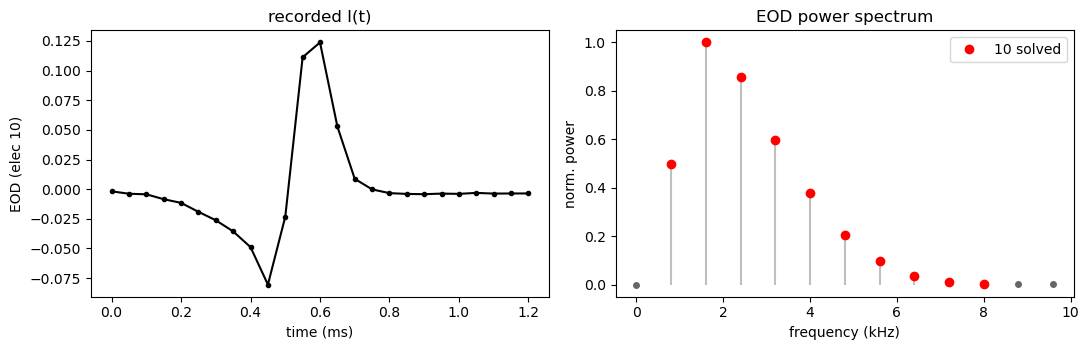

In [8]:
E, best, dt = load_eod_row("first_100_eods.csv", row=0, fs=20000.0)
I_rec = E[best]
keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt)
print(f"electrode #{best+1} | {n_t} samples @ {1/dt/1e3:.0f} kHz | solving {len(keep)} freqs: "
      f"{np.round(freqs[keep]/1e3,2)} kHz")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(n_t)*dt*1e3, I_rec - I_rec.mean(), 'ko-', ms=3)
ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel(f"EOD (elec {best+1})"); ax[0].set_title("recorded I(t)")
ax[1].vlines(freqs/1e3, 0, Pw/Pw.max(), color='0.75'); ax[1].plot(freqs/1e3, Pw/Pw.max(), 'o', color='0.4', ms=4)
ax[1].plot(freqs[keep]/1e3, (Pw/Pw.max())[keep], 'ro', label=f"{len(keep)} solved")
ax[1].set_xlabel("frequency (kHz)"); ax[1].set_ylabel("norm. power"); ax[1].set_title("EOD power spectrum"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Time-domain field, solving only the kept frequencies

`phi_hat(ω) = Ihat(ω) · psi(ω)`, where `psi` is the transfer function (unit source). Inverse-FFT -> `φ(t)` at the probe cells.

Resistive shortcut: if `eps=0` everywhere, `gamma` is real and ω-independent, so we solve **once** and scale by `I(t)` (no frequency loop).

In [9]:
def solve_eod_field(I_rec, dt, masks, N, source_fish, probes, power_keep=0.999, **mat):
    """phi(t) at probe cells. Fish `source_fish` emits (its body skipped from gamma);
       the OTHER fish are two-layer boundaries. Loops only over kept EOD frequencies."""
    h = 1.0/(N-1)
    tail, head = fish_axis_from_mask(masks[source_fish])
    pos, cur = multipole_sources(tail, head, n=8, I0=1.0)
    b_unit = build_multipole_b(pos, cur, h, N)

    sigma, eps, layers = material_layers(masks, N, skip=source_fish, **mat)   # geometry once
    resistive = not np.any(eps != 0.0)

    keep, om, Ihat, n_t, freqs, Pw = eod_frequencies(I_rec, dt, power_keep)
    pidx = [idx(i, j, N) for i, j in probes]

    if resistive:                                          # one solve, scale by I(t)
        A = build_A_gamma(sigma.astype(complex), N)
        psi = solve_potential(A, b_unit)[pidx].real
        phi_t = np.outer(I_rec - I_rec.mean(), psi)
    else:                                                  # frequency loop
        phi_hat = np.zeros((len(Ihat), len(probes)), complex)
        for k in keep:
            A = build_A_gamma(sigma + 1j*om[k]*eps, N)
            phi_hat[k] = Ihat[k] * solve_potential(A, b_unit)[pidx]
        phi_t = np.fft.irfft(phi_hat, n=n_t, axis=0)
    return phi_t, dict(pos=pos, cur=cur, sigma=sigma, eps=eps, layers=layers,
                       keep=keep, freqs=freqs, Pw=Pw, n_t=n_t)

## 7. Per-fish solve: each of the 4 fish as source, others as boundaries

Field snapshot at the dominant EOD frequency, with two-layer bodies outlined (source = dashed yellow, others: interior solid / skin dotted).

field snapshots at dominant freq = 1.6 kHz


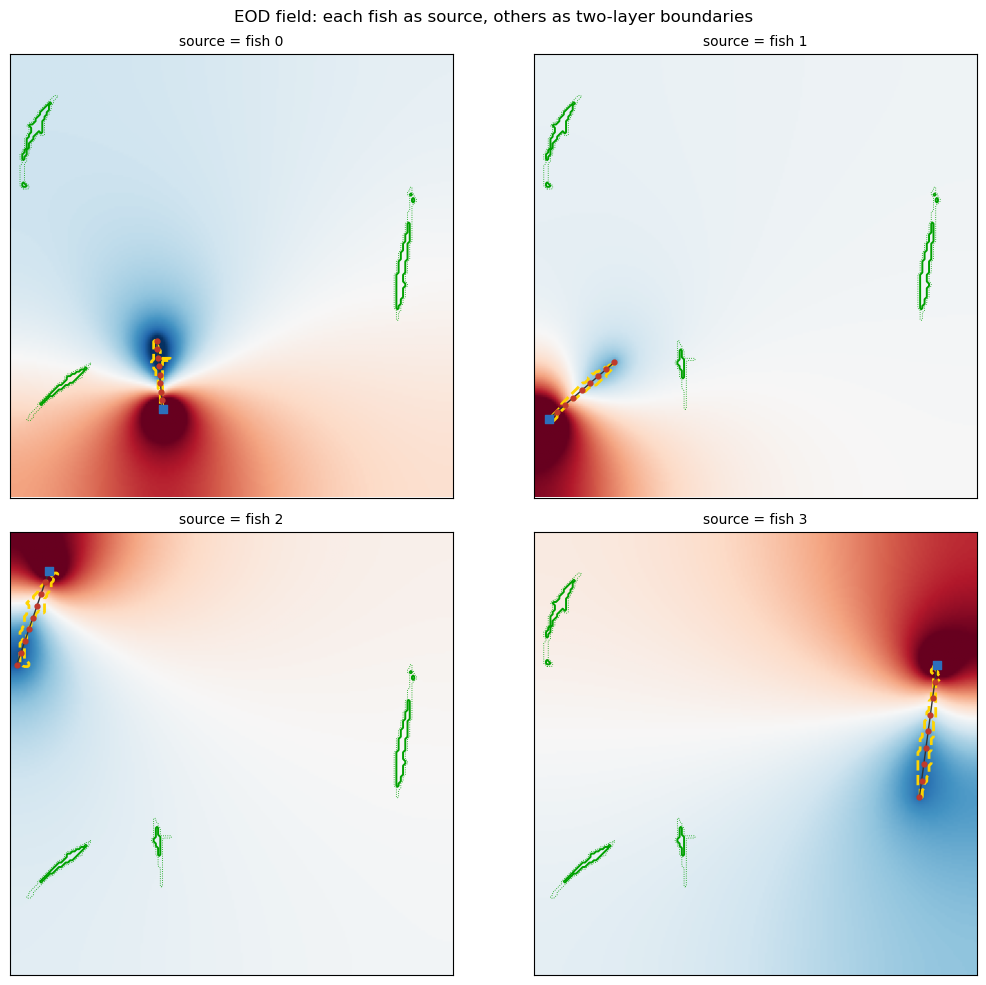

In [10]:
N = 200; h = 1.0/(N-1); g = np.linspace(0, 1, N)
n_fish = fish_mask.shape[0]
kdom = keep[np.argmax(Pw[keep])]                          # dominant EOD frequency bin
print(f"field snapshots at dominant freq = {freqs[kdom]/1e3:.1f} kHz")

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for sf, ax in zip(range(n_fish), axes.ravel()):
    tail, head = fish_axis_from_mask(fish_mask[sf])
    pos, cur = multipole_sources(tail, head, n=8, I0=1.0)
    b_unit = build_multipole_b(pos, cur, h, N)
    sigma, eps, layers = material_layers(fish_mask, N, skip=sf, **MAT)
    phi = to_grid(solve_potential(build_A_gamma(sigma + 1j*om[kdom]*eps, N), b_unit), N).real

    vmax = np.percentile(np.abs(phi), 99)
    ax.imshow(phi.T, origin='lower', extent=[0,1,0,1], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.contour(g, g, mask_to_grid(fish_mask[sf], N).T.astype(float), levels=[0.5],
               colors='#FFD400', linewidths=2, linestyles='--')                    # source (dashed)
    ax.plot(pos[:,0], pos[:,1], '-', color='0.2', lw=1)
    ax.scatter(*pos[cur>0].T, c='#C0392B', s=12, zorder=5)
    ax.scatter(*pos[cur<0].T, marker='s', c='#2C6FBB', s=30, zorder=5)
    for f,(interior, skin) in layers.items():                                       # other fish
        ax.contour(g, g, interior.T.astype(float), levels=[0.5], colors='#00A000', linewidths=1.4)
        ax.contour(g, g, (interior|skin).T.astype(float), levels=[0.5], colors='#00A000',
                   linewidths=0.6, linestyles=':')
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"source = fish {sf}", fontsize=10)
plt.suptitle("EOD field: each fish as source, others as two-layer boundaries", fontsize=12)
plt.tight_layout(); plt.show()

## 8. Waveform on the sensing skin: resistive vs capacitive

Probe = skin cells of a sensing fish. A **resistive** body rescales the EOD; a **capacitive** skin **distorts** it — the B-receptor signal.

source = fish 0, sensing = fish 1, 21 probe cells


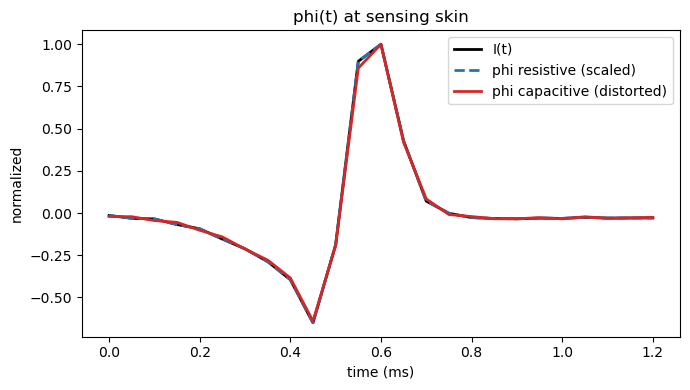

waveform distortion (capacitive vs resistive): 4.03e-02


In [11]:
source_fish = 0
sensing_fish = 1
sens = material_layers(fish_mask, N, **MAT)[2].get(sensing_fish)
if sens is None:
    raise ValueError("sensing fish absent this frame")
interior, skin = sens
probes = list(zip(*np.nonzero(skin)))[::3]                # subsample skin cells
print(f"source = fish {source_fish}, sensing = fish {sensing_fish}, {len(probes)} probe cells")

phi_res, info = solve_eod_field(I_rec, dt, fish_mask, N, source_fish, probes,
                                **{**MAT, 'eps_skin': 0.0})          # resistive skin
phi_cap, _    = solve_eod_field(I_rec, dt, fish_mask, N, source_fish, probes, **MAT)  # capacitive skin

t = np.arange(info['n_t'])*dt
nr = lambda x: x/np.max(np.abs(x))
plt.figure(figsize=(7,4))
plt.plot(t*1e3, nr(I_rec-I_rec.mean()), 'k', lw=2, label="I(t)")
plt.plot(t*1e3, nr(phi_res[:,0]), '--', color="#1f77b4", lw=2, label="phi resistive (scaled)")
plt.plot(t*1e3, nr(phi_cap[:,0]),        color="#d62728", lw=2, label="phi capacitive (distorted)")
plt.xlabel("time (ms)"); plt.ylabel("normalized"); plt.title("phi(t) at sensing skin"); plt.legend()
plt.tight_layout(); plt.show()

err = np.abs(nr(phi_cap[:,0]) - nr(phi_res[:,0])).max()
print(f"waveform distortion (capacitive vs resistive): {err:.2e}")